# IBM HR Analytics Employee Attrition & Performance

**Source:** [IBM HR Analytics Employee Attrition & Performance on Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

## Dataset overview

This fictional dataset was created by IBM data scientists to explore patterns associated with employee attrition.

Example questions to investigate:

- How does distance from home vary by job role and attrition status?
- How does average monthly income differ by education level and attrition status?

## Category codes

The following tables explain the numeric codes used in the dataset.

### Education

| Code | Education level |
| --- | --- |
| 1 | Below College |
| 2 | College |
| 3 | Bachelor |
| 4 | Master |
| 5 | Doctor |

### Satisfaction and involvement

These four columns share the same rating scale:

- `EnvironmentSatisfaction`
- `JobInvolvement`
- `JobSatisfaction`
- `RelationshipSatisfaction`

| Code | Rating |
| --- | --- |
| 1 | Low |
| 2 | Medium |
| 3 | High |
| 4 | Very High |

### Performance rating (`PerformanceRating`)

| Code | Rating |
| --- | --- |
| 1 | Low |
| 2 | Good |
| 3 | Excellent |
| 4 | Outstanding |

### Work–life balance (`WorkLifeBalance`)

| Code | Rating |
| --- | --- |
| 1 | Bad |
| 2 | Good |
| 3 | Better |
| 4 | Best |

### Target column (`Attrition`)

**Employee attrition** means employees leaving the company. `Attrition` is the target column: the outcome a classification model aims to predict using the other employee attributes.

| Value | Meaning |
| --- | --- |
| `Yes` | The employee left the company. |
| `No` | The employee stayed with the company. |

This is a **binary classification** target because it has two possible classes. The column records whether an employee left, but does not specify why they left.

An **attrition rate** is the percentage of employees in a group whose `Attrition` value is `Yes`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
from matplotlib import colormaps
from matplotlib.colors import to_hex

# The variable and functions below allow the correct conversion to LaTeX tables when exporting to PDF with nbconvert.
def correctness_html(value):
    return {
        'Yes': 'color: green; font-weight: bold;',
        'No': 'color: red; font-weight: bold;',
    }.get(value, '')


def _blues(value):
    """Map a value in [0, 1] to a 'Blues' hex colour and whether it is dark."""
    r, g, b, _ = colormaps["Blues"](float(value))
    return to_hex((r, g, b))[1:].upper(), (0.299 * r + 0.587 * g + 0.114 * b) < 0.5


def gradient_html(value):
    hex_code, dark = _blues(value)
    return f"background-color: #{hex_code}; color: {'white' if dark else 'black'};"


def gradient_latex(value):
    hex_code, dark = _blues(value)
    return f"cellcolor:[HTML]{{{hex_code}}}; color:{{{'white' if dark else 'black'}}};"

def correctness_latex(value):
    return {
        'Yes': 'color:{green}; bfseries:;',
        'No': 'color:{red}; bfseries:;',
    }.get(value, '')


def display_table(
        df,
        formats=None,
        latex_formats=None,
        html_style=None,
        latex_style=None,
        style_columns=None,
        hide_index=True,
        fit_to_page=False,
        na_rep=None,
        multipage=None,
):
    r"""
    Display a DataFrame as HTML and LaTeX for notebook viewing and PDF export.

    Formats values without modifying the DataFrame. The LaTeX version includes
    alternating row shading, bold headers, and escaped row and column labels.

    Parameters
    ----------
    df : pandas.DataFrame
        Table to display.
    formats : dict, optional
        Column names mapped to format strings or formatting functions.
        Used for both outputs unless overridden by latex_formats.
    latex_formats : dict, optional
        Formatting overrides for LaTeX output. Formatters that generate special
        characters must escape them, for example '%' as r'\%'.
    html_style : callable, optional
        Function receiving a cell value and returning a CSS style string.
        Return an empty string to leave the cell unchanged.
    latex_style : callable, optional
        Function receiving a cell value and returning a pandas LaTeX style
        string, such as 'color:{green}; bfseries:;'.
    style_columns : list of str, optional
        Columns to which the styling functions apply. If None, apply them
        to all data cells. Callbacks receive original, unformatted values.
    hide_index : bool, default True
        Hide row indexes in both output formats.
    fit_to_page : bool, default False
        Shrink the LaTeX table if it exceeds the PDF text width.
        Does not affect the HTML display.
    na_rep : str or None, default None
        Text displayed for missing values. If None, use the default rendering
        without a custom replacement. Does not modify the underlying data.

    multipage : bool or None, default None
        Use a LaTeX longtable with repeated headers and page breaks.
        None enables this unless fit_to_page=True. Explicitly combining
        multipage=True and fit_to_page=True raises ValueError.

    Returns
    -------
    None
        Displays HTML and LaTeX representations through IPython.display.

    Notes
    -----
    The PDF template must load xcolor and colortbl for LaTeX styling,
    longtable for multipage tables, and adjustbox when fit_to_page=True.
    Rerun and save the cell outputs before exporting without execution.
    """
    if multipage is None:
        multipage = not fit_to_page
    if multipage and fit_to_page:
        raise ValueError('Multipage tables cannot use fit_to_page=True; disable resizing.')

    formats = formats or {}
    pdf_formats = {**formats, **(latex_formats or {})}

    html = df.style.format(formats, na_rep=na_rep, escape='html')

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(
                lambda value: r"\textbf{" + _tex(value) + "}",
                axis=1,
            )
        )
    else:
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(escape='latex', axis=1)
        )

    if hide_index:
        html = html.hide(axis='index')
        latex = latex.hide(axis='index')

    # Apply LaTeX row shading and bold labels.
    def stripe_rows(values):
        return [
            'cellcolor:{gray!10}--rwrap;' if i % 2 == 0 else ''
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + 'bfseries:;' for style in stripe_rows(values)]

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
        )
    else:
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
            .map_index(lambda value: 'bfseries:;', axis=1)
        )

    # Apply caller-supplied styles to selected columns.
    # If style_columns is None, apply to all data cells.
    if html_style is not None:
        html = html.map(html_style, subset=style_columns)

    if latex_style is not None:
        latex = latex.map(latex_style, subset=style_columns)

    latex_output = latex.to_latex(
        environment='longtable' if multipage else None,
    )

    if fit_to_page:
        latex_output = (
                r"\begin{adjustbox}{max width=\linewidth}" "\n"
                + latex_output
                + "\n" r"\end{adjustbox}"
        )

    display({
        'text/html': html.to_html(),
        'text/latex': latex_output,
    }, raw=True)


# display_estimator: show a scikit-learn model as the interactive HTML diagram in the notebook,
# and as an equivalent boxed LaTeX diagram when exporting to PDF with nbconvert
# (nbconvert cannot render the HTML diagram and would otherwise fall back to plain text).
import inspect
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline
from sklearn.utils import estimator_html_repr


def _tex(text):
    """Escape LaTeX special characters."""
    rep = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#',
           '_': r'\_', '{': r'\{', '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(rep.get(ch, ch) for ch in str(text))


def _changed_params(est):
    """Parameters that differ from their defaults (nested estimators are drawn as boxes instead)."""
    defaults = inspect.signature(type(est).__init__).parameters
    shown = []
    for name, value in est.get_params(deep=False).items():
        if name == 'steps' or isinstance(value, BaseEstimator):
            continue
        default = defaults[name].default if name in defaults else inspect.Parameter.empty
        try:
            if value is default or value == default:
                continue
        except Exception:  # e.g. arrays, where == is element-wise
            pass
        text = value.__name__ if callable(value) and hasattr(value, '__name__') else repr(value)
        shown.append(f"{name}={text}")
    return shown


def _estimator_latex(est, name=None, depth=0):
    """Nested boxes: one per estimator, pipeline steps joined by arrows."""
    fill = ['gray!12', 'white', 'blue!6'][depth % 3]
    if isinstance(est, str):  # e.g. 'passthrough' / 'drop' pipeline steps
        return r'\fcolorbox{gray}{' + fill + r'}{\texttt{' + _tex(f"{name}: {est}") + '}}'
    title = type(est).__name__ if name is None else f"{name}: {type(est).__name__}"
    rows = [r'\textbf{' + _tex(title) + '}']
    rows += [r'\footnotesize\texttt{' + _tex(p) + '}' for p in _changed_params(est)]
    if isinstance(est, Pipeline):
        children = [_estimator_latex(step, step_name, depth + 1) for step_name, step in est.steps]
        rows.append(r'\begin{tabular}{c}' + r' \\ $\downarrow$ \\ '.join(children) + r'\end{tabular}')
    else:
        nested = [(n, v) for n, v in est.get_params(deep=False).items() if isinstance(v, BaseEstimator)]
        if nested:
            children = [_estimator_latex(v, n, depth + 1) for n, v in nested]
            rows.append(r'\begin{tabular}{c}' + r' \\ '.join(children) + r'\end{tabular}')
    return r'\fcolorbox{gray}{' + fill + r'}{\begin{tabular}{c}' + r' \\ '.join(rows) + r'\end{tabular}}'


def display_estimator(est):
    """Display a scikit-learn estimator for both notebook viewing (HTML) and PDF export (LaTeX)."""
    display({
        'text/html': estimator_html_repr(est),
        'text/latex': r'\begin{center}' + _estimator_latex(est) + r'\end{center}',
        'text/plain': repr(est),
    }, raw=True)

Show me a breakdown of distance from home by job role and attrition

In [3]:
from IPython.core.display import Markdown

breakdown = (
    df.groupby(["JobRole", "Attrition"])["DistanceFromHome"]
    .agg(
        Employees="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max",
    )
)

'''display(
    breakdown.reset_index()
    .style
    .hide(axis="index")
    .format({"Mean": "{:.2f}", "Median": "{:.1f}"})
    .set_caption("Distance from home by job role and attrition")
)'''

display(Markdown("**Distance from home by job role and attrition**"))
display_table(
    breakdown.reset_index(),
    formats={"Mean": "{:.2f}", "Median": "{:.1f}"},
    html_style=correctness_html,
    latex_style=correctness_latex,
    style_columns=["Attrition"],
)

**Distance from home by job role and attrition**

JobRole,Attrition,Employees,Mean,Median,Minimum,Maximum
Healthcare Representative,No,122,9.20,7.0,1,29
Healthcare Representative,Yes,9,17.67,20.0,2,29
Human Resources,No,40,6.60,3.5,1,26
Human Resources,Yes,12,13.42,15.0,1,23
Laboratory Technician,No,197,9.33,7.0,1,29
Laboratory Technician,Yes,62,9.66,7.0,1,29
Manager,No,97,7.93,4.0,1,29
Manager,Yes,5,10.00,2.0,2,29
Manufacturing Director,No,135,9.53,7.0,1,29
Manufacturing Director,Yes,10,8.80,7.5,1,23


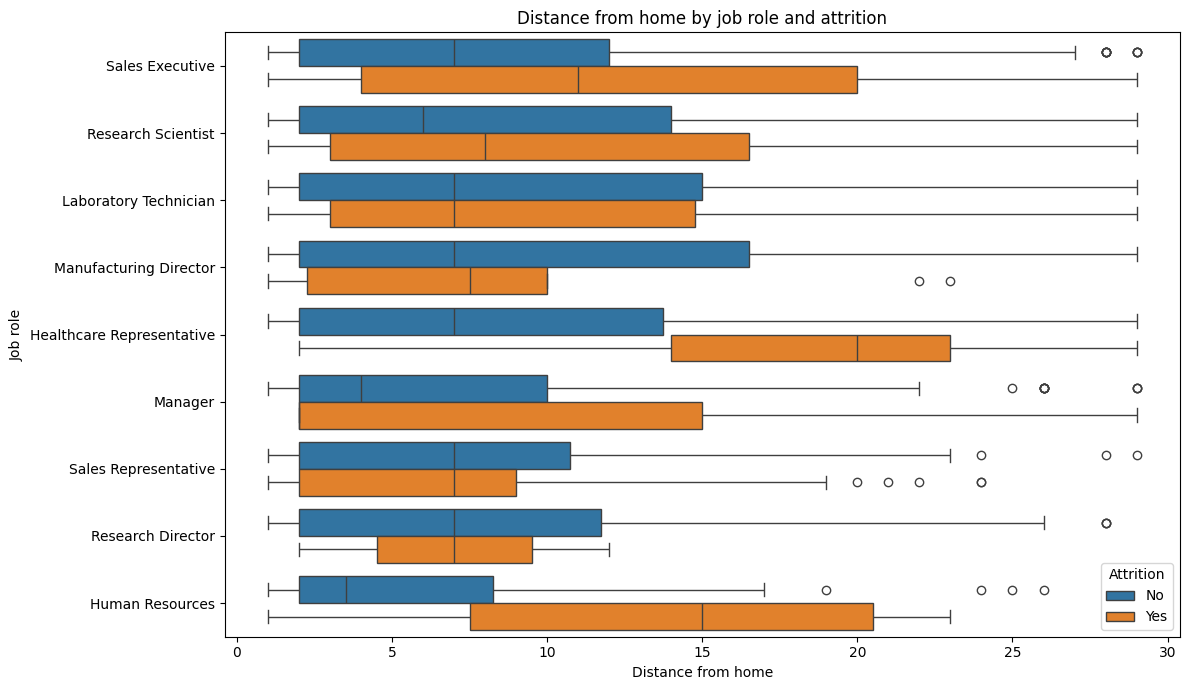

In [4]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="DistanceFromHome",
    y="JobRole",
    hue="Attrition",
    hue_order=["No", "Yes"],
    ax=ax,
)

ax.set_title("Distance from home by job role and attrition")
ax.set_xlabel("Distance from home")
ax.set_ylabel("Job role")
ax.legend(title="Attrition")
fig.tight_layout()
plt.show()

Compare average monthly income by education and attrition

In [5]:
education_labels = {
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor",
}

income_breakdown = (
    df.groupby(["Education", "Attrition"])["MonthlyIncome"]
    .agg(Employees="count", AverageMonthlyIncome="mean")
    .reset_index()
)

income_breakdown["Education"] = (
    income_breakdown["Education"].map(education_labels)
)

'''display(
    income_breakdown.style
    .hide(axis="index")
    .format({"AverageMonthlyIncome": "{:,.2f}"})
    .set_caption("Average monthly income by education and attrition")
)'''

display(Markdown("**Average monthly income by education and attrition**"))
display_table(income_breakdown, formats={"AverageMonthlyIncome": "{:,.2f}"},
              html_style=correctness_html,
              latex_style=correctness_latex,
              style_columns=["Attrition"],
)

**Average monthly income by education and attrition**

Education,Attrition,Employees,AverageMonthlyIncome
Below College,No,139,"5,926.13"
Below College,Yes,31,"4,360.16"
College,No,238,"6,586.06"
College,Yes,44,"4,282.55"
Bachelor,No,473,"6,882.92"
Bachelor,Yes,99,"4,770.24"
Master,No,340,"7,087.81"
Master,Yes,58,"5,335.16"
Doctor,No,43,"8,559.91"
Doctor,Yes,5,"5,850.20"


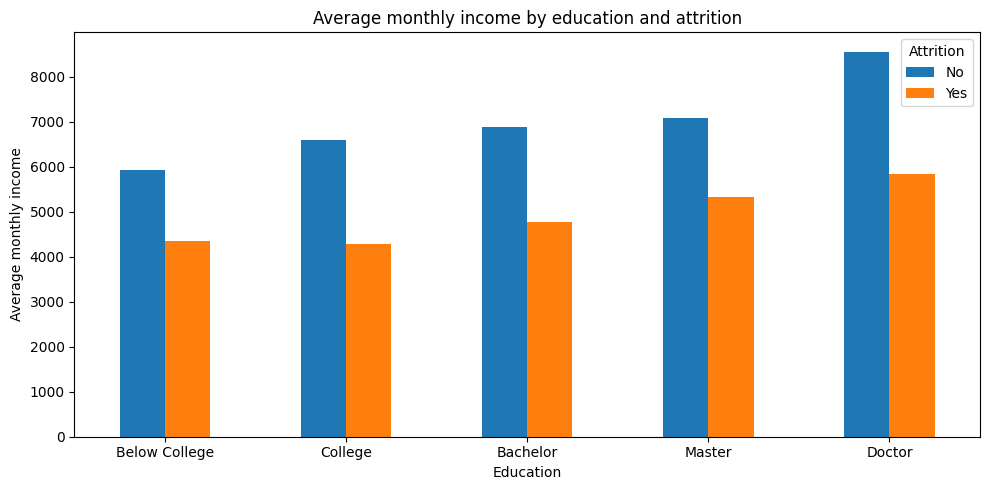

In [6]:
income_comparison = income_breakdown.pivot(
    index="Education",
    columns="Attrition",
    values="AverageMonthlyIncome",
).reindex(education_labels.values())

ax = income_comparison.plot.bar(
    figsize=(10, 5),
    rot=0,
    title="Average monthly income by education and attrition",
)

ax.set_xlabel("Education")
ax.set_ylabel("Average monthly income")
ax.legend(title="Attrition")
plt.tight_layout()
plt.show()

## Conclusion

In this fictional IBM employee dataset, the comparisons show a consistent income pattern and a mixed distance pattern:

- **Monthly income:** Employees who left had lower average monthly incomes at every education level. For example, employees with a Bachelor's education who left earned an average of **4,770.24**, compared with **6,882.92** for those who stayed.
- **Distance from home:** In most job roles, employees who left lived farther from work. The difference is clearest for **Healthcare Representatives, Human Resources and Sales Executives**, where both the mean and the median distance are much higher for leavers. For Managers, Manufacturing Directors, Research Directors and Sales Representatives, the mean and median point in different directions or barely differ. These roles also have very few leavers (only 2 for Research Directors and 5 for Managers), so their pattern isn't reliable. The boxplot shows medians (the middle line); the white diamonds show means.
- **Group sizes:** Some averages are based on very few employees who left, including **2 Research Directors** and **5 Managers**. These comparisons should be interpreted cautiously.

Overall, lower income and greater distance from home are associated with attrition in these comparisons, but the distance pattern is not consistent across all job roles. These results **do not establish that either factor causes employees to leave**. Other attributes, such as seniority, job role, and overtime, may help explain the differences.

These tables compare average income and distance between employees who left and those who stayed; they do not directly measure attrition rates within income or distance bands. A useful next step is to calculate the **percentage of employees who left within each income and distance band**, alongside the number of employees in each group.

The findings describe this fictional dataset and should not be treated as evidence about real employees.